# CAISO 2025 Production and Curtailment EDA

**Source:** `Data_ML_SQL/CASIO_production_and_curtailments_2025.xlsx`  
**Project question:** Can these system-level time series help predict whether a proposed solar interconnection project will eventually become commercially operational before it is withdrawn?

This notebook loads **every workbook sheet**, audits quality and timestamp semantics, converts five-minute MW observations to MWh, analyzes production and curtailment distributions and time patterns, and makes an explicit recommendation for the classifier, SQL layer, RAG corpus, and agent.

## Decision framing

The defensible queue-model target is **eventual commercial operation before withdrawal**, not “active versus withdrawn” and not generic “accepted versus rejected.” Operational and withdrawn are terminal outcomes; active projects are unresolved/right-censored. This workbook has no project IDs or queue outcomes, so it cannot supply labels for that classifier.

## 1. Environment and workbook inventory

In [1]:
# Install only missing dependencies. In a prepared project environment this performs no downloads.
import importlib.util
import subprocess
import sys

required_packages = {
    "openpyxl": "openpyxl",
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
}
missing_packages = [package for module, package in required_packages.items() if importlib.util.find_spec(module) is None]
if missing_packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing_packages])

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 13
RANDOM_SEED = 42
INTERVAL_HOURS = 5 / 60

In [2]:
candidates = [
    Path("Data_ML_SQL/CASIO_production_and_curtailments_2025.xlsx"),
    Path("../Data_ML_SQL/CASIO_production_and_curtailments_2025.xlsx"),
]
workbook_path = next((path for path in candidates if path.exists()), None)
if workbook_path is None:
    raise FileNotFoundError("Could not locate CASIO_production_and_curtailments_2025.xlsx")

excel_file = pd.ExcelFile(workbook_path)
sheet_names = excel_file.sheet_names
raw_sheets = pd.read_excel(workbook_path, sheet_name=None)

inventory = pd.DataFrame(
    [{"sheet": name, "rows": frame.shape[0], "columns": frame.shape[1]} for name, frame in raw_sheets.items()]
)
print(f"Workbook: {workbook_path.resolve()}")
print(f"Sheets loaded: {sheet_names}")
display(inventory)
assert set(sheet_names) == set(raw_sheets), "Not all sheets were loaded."

Workbook: /Users/alexanderbarriga/Agentic_Interconnection_Risk /Data_ML_SQL/CASIO_production_and_curtailments_2025.xlsx
Sheets loaded: ['Read_me', 'Production', 'Curtailments']


,sheet,rows,columns
0,Read_me,0,1
1,Production,105120,14
2,Curtailments,25848,6


In [3]:
# Preserve and display the documentation sheet because its caveats govern interpretation.
read_me = raw_sheets["Read_me"].copy()
display(read_me.fillna("").style.hide(axis="index"))

"This file contains two sets of information: Production data and curtailments data. This data is similar to the information provided in daily renewable and curtailments reports, respectively, but in five-minute intervals. Given the five-minute granularity, there is potential for mismatches when compared to the hourly data provided in the daily reports. These files contain raw data, and while the ISO has reviewed for accuracy, the data is provided as is, and is not considered operational or settlement quality data. All data is in megawatt (MW) units. The production table provides supply and demand information. For the demand, actual load and net load (actual load less wind production less solar production) are provided. For the supply, the production data is broken out by technology including: - solar and wind - renewable, which includes solar, wind, biomass, biogas, geothermal and small hydropower - thermal, which includes thermal production from different technologies with the exception of nuclear and geothermal - large hydropower, which is not classified as renewable - imports coming into the ISO area, which is the net actual interchange. - total production, which is the sum of all internal supply including renewable, large hydro, nuclear and thermal. The last column of Load less (generation and import) is to verify that supply matches demand. The curtailment table provides solar and wind curtailments per interval; only intervals in which a curtailment was observed are listed. The amounts of curtailments are not counted in the production quantities."


**Source caveats from `Read_me`:** the values are raw/non-settlement quality; observations are five-minute MW; production excludes curtailed energy; and the Curtailments sheet contains only intervals in which curtailment was reported. Consequently, missing curtailment rows are not equivalent to measured zeros outside the sheet's actual date coverage.

## 2. Standardization, schema, and data quality

In [4]:
def snake_case(value):
    value = re.sub(r"[^0-9a-zA-Z]+", "_", str(value).strip())
    return value.strip("_").lower()

production = raw_sheets["Production"].copy()
curtailments = raw_sheets["Curtailments"].copy()
production.columns = [snake_case(column) for column in production.columns]
curtailments.columns = [snake_case(column) for column in curtailments.columns]

production["date"] = pd.to_datetime(production["date"], errors="coerce")
curtailments["date"] = pd.to_datetime(curtailments["date"], errors="coerce")

print("Production columns:", production.columns.tolist())
print("Curtailment columns:", curtailments.columns.tolist())
display(production.head(3))
display(curtailments.head(3))

Production columns: ['date', 'hour', 'interval', 'load', 'solar', 'wind', 'net_load', 'renewables', 'nuclear', 'large_hydro', 'imports', 'generation', 'thermal', 'load_less_generation_imports']
Curtailment columns: ['date', 'hour', 'interval', 'wind_curtailment', 'solar_curtailment', 'reason']


,date,hour,interval,load,solar,wind,net_load,renewables,nuclear,large_hydro,imports,generation,thermal,load_less_generation_imports
0,2025-01-01 00:00:00,1,1,"21,921.839",0.000,938.760,"20,983.079","2,352.401","2,274.445","2,123.097","6,023.107","15,898.799","9,148.856",-0.066
1,2025-01-01 00:05:00,1,2,"21,948.505",0.000,928.299,"21,020.207","2,337.166","2,274.717","2,036.343","6,199.653","15,748.844","9,100.618",0.008
2,2025-01-01 00:10:00,1,3,"21,887.137",0.000,888.384,"20,998.754","2,294.833","2,274.345","2,031.954","6,387.520","15,499.575","8,898.443",0.042


,date,hour,interval,wind_curtailment,solar_curtailment,reason
0,2025-01-01 08:00:00,11,7,NaN,5.300,Local
1,2025-01-01 08:00:00,11,9,NaN,1.450,Local
2,2025-01-01 08:00:00,11,10,NaN,3.580,Local


In [5]:
def quality_profile(frame):
    rows = len(frame)
    records = []
    for column in frame.columns:
        non_null = frame[column].dropna()
        python_types = non_null.map(lambda value: type(value).__name__).nunique()
        records.append({
            "column": column,
            "dtype": str(frame[column].dtype),
            "missing_n": int(frame[column].isna().sum()),
            "missing_pct": float(frame[column].isna().mean() * 100),
            "unique_n": int(frame[column].nunique(dropna=True)),
            "python_type_count": int(python_types),
        })
    return pd.DataFrame(records)

production_quality = quality_profile(production)
curtailment_quality = quality_profile(curtailments)

print("Production quality")
display(production_quality)
print("Curtailment quality")
display(curtailment_quality)
print("Duplicate full production rows:", int(production.duplicated().sum()))
print("Duplicate full curtailment rows:", int(curtailments.duplicated().sum()))

Production quality


,column,dtype,missing_n,missing_pct,unique_n,python_type_count
0,date,datetime64[us],0,0.000,105108,1
1,hour,int64,0,0.000,24,1
2,interval,int64,0,0.000,12,1
3,load,float64,0,0.000,105105,1
4,solar,float64,0,0.000,58635,1
5,wind,float64,0,0.000,105120,1
6,net_load,float64,0,0.000,105120,1
7,renewables,float64,0,0.000,105120,1
8,nuclear,float64,0,0.000,104255,1
9,large_hydro,float64,0,0.000,103602,1


Curtailment quality


,column,dtype,missing_n,missing_pct,unique_n,python_type_count
0,date,datetime64[us],0,0.000,151,1
1,hour,int64,0,0.000,24,1
2,interval,int64,0,0.000,12,1
3,wind_curtailment,float64,9308,36.011,16047,1
4,solar_curtailment,float64,5303,20.516,20332,1
5,reason,str,0,0.000,2,1


Duplicate full production rows: 0
Duplicate full curtailment rows: 0


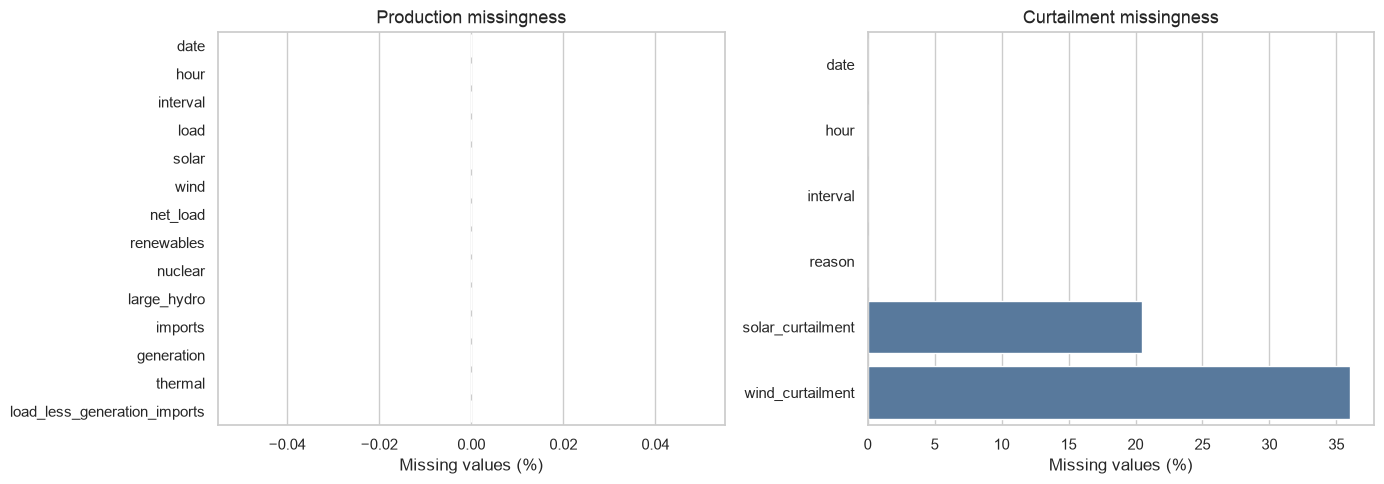

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for axis, profile, title in [
    (axes[0], production_quality, "Production missingness"),
    (axes[1], curtailment_quality, "Curtailment missingness"),
]:
    plot_data = profile.sort_values("missing_pct", ascending=True)
    sns.barplot(data=plot_data, x="missing_pct", y="column", ax=axis, color="#4C78A8")
    axis.set_title(title)
    axis.set_xlabel("Missing values (%)")
    axis.set_ylabel("")
plt.tight_layout()
plt.show()

Curtailment-value nulls require special treatment. A row may report only solar or only wind, so a null in the other technology field is structural within a reported event row. We use zero only while aggregating those reported rows. We do **not** fill unobserved dates after the sheet ends with zeros.

## 3. Timestamp semantics and calendar completeness

In [7]:
# Production's date field is already the five-minute interval timestamp.
production = production.rename(columns={"date": "timestamp"})
production["expected_hour"] = production["timestamp"].dt.hour + 1
production["expected_interval"] = production["timestamp"].dt.minute.floordiv(5) + 1
production["hour_consistent"] = production["hour"].eq(production["expected_hour"])
production["interval_consistent"] = production["interval"].eq(production["expected_interval"])

expected_rows = 365 * 24 * 12
duplicate_timestamp_n = int(production["timestamp"].duplicated(keep=False).sum())
unique_timestamp_n = int(production["timestamp"].nunique())

print("Production date range:", production["timestamp"].min(), "to", production["timestamp"].max())
print("Rows / expected 5-minute rows:", len(production), "/", expected_rows)
print("Unique timestamps:", unique_timestamp_n)
print("Rows belonging to duplicated wall-clock timestamps:", duplicate_timestamp_n)
print("Hour coding consistency:", production["hour_consistent"].mean())
print("Interval coding consistency:", production["interval_consistent"].mean())

full_wall_clock = pd.date_range("2025-01-01", "2025-12-31 23:55", freq="5min")
missing_wall_clock = full_wall_clock.difference(production["timestamp"])
duplicated_wall_clock = production.loc[production["timestamp"].duplicated(keep=False), "timestamp"].sort_values()
print("Missing wall-clock timestamps:", len(missing_wall_clock))
print("Duplicated wall-clock rows:", len(duplicated_wall_clock))
display(pd.DataFrame({"missing_spring_DST": missing_wall_clock}))
display(duplicated_wall_clock.to_frame(name="duplicated_fall_DST").reset_index(drop=True))

Production date range: 2025-01-01 00:00:00 to 2025-12-31 23:55:00
Rows / expected 5-minute rows: 105120 / 105120
Unique timestamps: 105108
Rows belonging to duplicated wall-clock timestamps: 24
Hour coding consistency: 1.0
Interval coding consistency: 1.0
Missing wall-clock timestamps: 12
Duplicated wall-clock rows: 24


,missing_spring_DST
0,2025-03-09 02:00:00
1,2025-03-09 02:05:00
2,2025-03-09 02:10:00
3,2025-03-09 02:15:00
4,2025-03-09 02:20:00
5,2025-03-09 02:25:00
6,2025-03-09 02:30:00
7,2025-03-09 02:35:00
8,2025-03-09 02:40:00
9,2025-03-09 02:45:00


,duplicated_fall_DST
0,2025-11-02 01:00:00
1,2025-11-02 01:00:00
2,2025-11-02 01:05:00
3,2025-11-02 01:05:00
4,2025-11-02 01:10:00
5,2025-11-02 01:10:00
6,2025-11-02 01:15:00
7,2025-11-02 01:15:00
8,2025-11-02 01:20:00
9,2025-11-02 01:20:00


In [8]:
# Curtailment Date carries a calendar date with an irrelevant time component.
# CAISO Hour is 1-based and Interval 1 corresponds to minute 00.
curtailment_calendar_date = curtailments["date"].dt.normalize()
curtailment_minutes = (curtailments["hour"] - 1) * 60 + (curtailments["interval"] - 1) * 5
curtailments["timestamp"] = curtailment_calendar_date + pd.to_timedelta(curtailment_minutes, unit="m")

# Validate the reconstruction against production's redundant Hour/Interval fields.
timestamp_reference = production[["timestamp", "hour", "interval"]].drop_duplicates()
validation = curtailments[["timestamp", "hour", "interval"]].merge(
    timestamp_reference,
    on=["timestamp", "hour", "interval"],
    how="left",
    indicator=True,
)
print("Curtailment date range:", curtailments["timestamp"].min(), "to", curtailments["timestamp"].max())
print("Rows matching production timestamp + Hour + Interval:", validation["_merge"].eq("both").mean())
print("Unique curtailed timestamps:", curtailments["timestamp"].nunique())
print("Rows in duplicated timestamp groups:", int(curtailments["timestamp"].duplicated(keep=False).sum()))
print("Unique reason values:", sorted(curtailments["reason"].dropna().astype(str).unique().tolist()))

Curtailment date range: 2025-01-01 10:30:00 to 2025-05-31 19:30:00
Rows matching production timestamp + Hour + Interval: 1.0
Unique curtailed timestamps: 21402
Rows in duplicated timestamp groups: 8892
Unique reason values: ['Local', 'System']


**DST policy:** preserve all physical five-minute observations, including both fall-back rows. Calendar-day energy therefore naturally has 23 hours on spring-forward day and 25 hours on fall-back day. A naive wall-clock timestamp cannot distinguish the two fall-back occurrences, so any later database implementation should add a sequence key or timezone-aware timestamp if the source exposes it.

**Coverage warning:** production covers the full year, while reported curtailment ends in May. All curtailment rates and joint analyses below are restricted to the observed curtailment window. Later missing months are never converted to zero.

## 4. Production distributions and physical checks

In [9]:
production_metrics = [
    "load", "solar", "wind", "net_load", "renewables", "nuclear",
    "large_hydro", "imports", "generation", "thermal",
]
production_summary = production[production_metrics].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
).T
production_summary["negative_n"] = (production[production_metrics] < 0).sum()
display(production_summary)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,negative_n
load,"105,120.000","25,689.589","4,169.069","15,570.050","19,035.244","20,306.929","22,622.485","25,016.856","27,830.912","33,992.609","38,214.645","44,434.831",0
solar,"105,120.000","6,534.791","7,858.844",0.000,0.000,0.000,0.000,190.995,"14,266.804","20,215.134","21,115.911","21,750.519",0
wind,"105,120.000","2,520.158","1,393.538",57.338,288.675,592.774,"1,324.156","2,327.583","3,685.508","4,888.755","5,548.747","6,295.463",0
net_load,"105,120.000","16,634.641","7,459.168","-1,341.943","1,377.454","3,759.836","10,204.296","18,437.575","21,807.433","27,011.523","32,606.211","39,764.452",217
renewables,"105,120.000","10,408.011","7,699.815","1,320.533","1,826.713","2,279.453","3,925.106","6,173.941","17,894.103","23,613.788","25,550.957","27,601.869",0
nuclear,"105,120.000","2,010.242",453.509,"1,123.901","1,130.547","1,133.279","1,698.379","2,264.708","2,272.032","2,280.144","2,282.501","2,310.434",0
large_hydro,"105,120.000","2,203.181","1,107.795",0.000,0.000,500.939,"1,362.962","2,145.360","2,967.960","4,167.859","4,723.695","5,373.155",0
imports,"105,120.000","3,539.709","3,387.128","-6,992.107","-4,742.512","-2,634.638","1,019.837","4,371.747","6,138.223","8,054.575","9,312.415","11,044.320",19861
generation,"105,120.000","22,149.880","6,049.307","9,671.559","12,106.224","13,827.361","17,414.184","21,311.118","26,034.062","33,358.993","37,619.819","46,035.233",0
thermal,"105,120.000","7,528.446","4,825.037","-1,132.350",227.042,"1,045.399","3,816.518","6,947.567","10,404.071","16,113.255","22,141.983","29,437.512",556


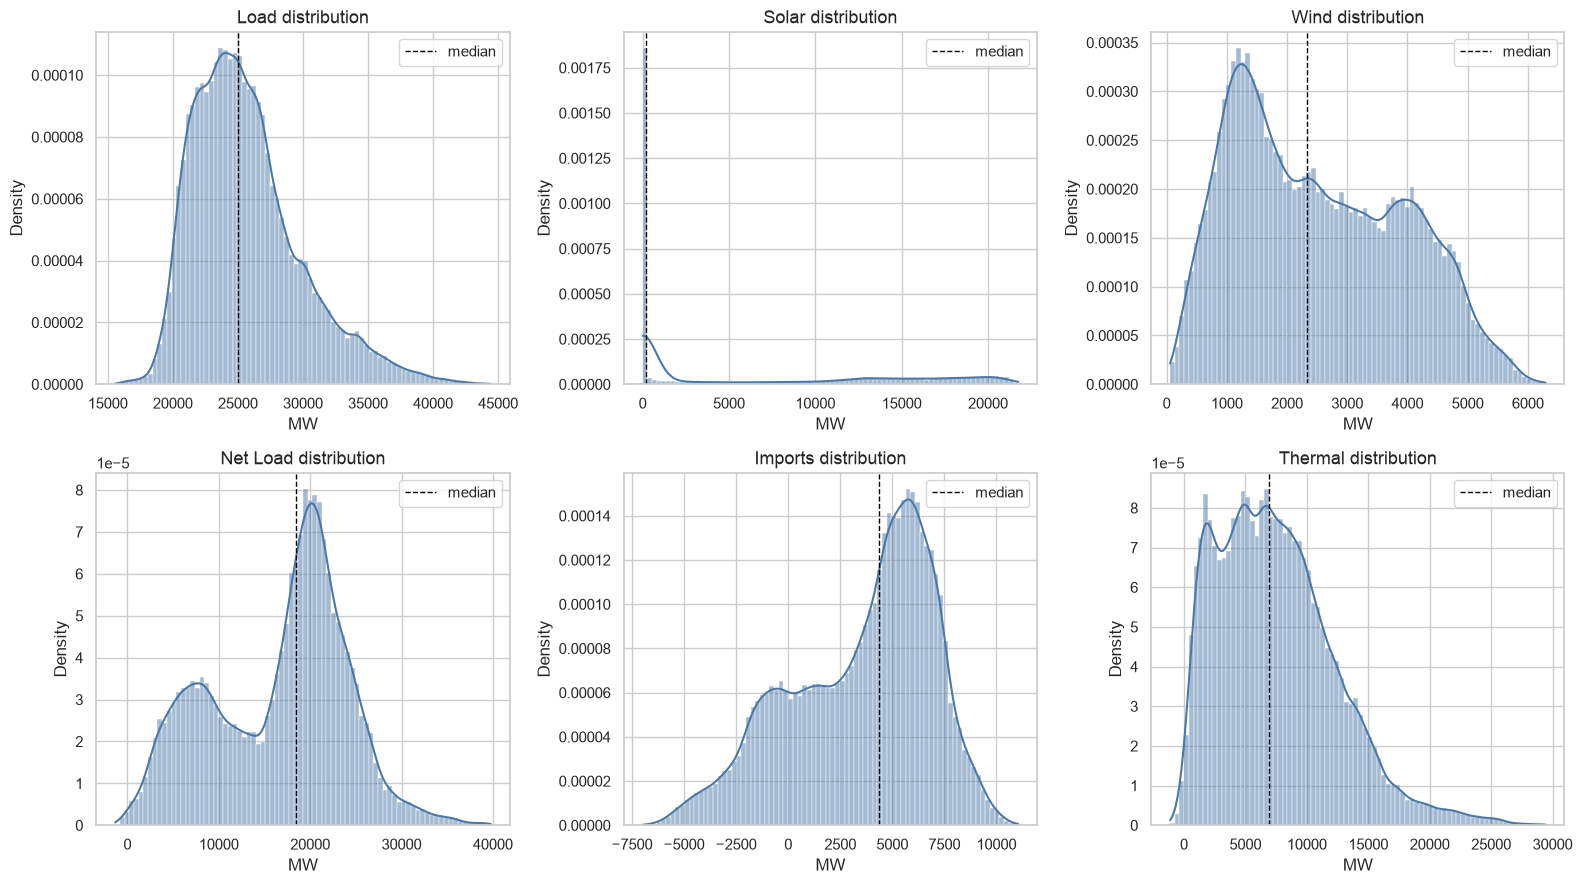

In [10]:
# Empirical probability distributions are preferable to imposing normality on seasonal grid data.
selected_metrics = ["load", "solar", "wind", "net_load", "imports", "thermal"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for metric, axis in zip(selected_metrics, axes.flat):
    sns.histplot(production[metric], bins=80, stat="density", kde=True, ax=axis, color="#4C78A8")
    axis.axvline(production[metric].median(), color="black", linestyle="--", linewidth=1, label="median")
    axis.set_title(f"{metric.replace('_', ' ').title()} distribution")
    axis.set_xlabel("MW")
    axis.legend()
plt.tight_layout()
plt.show()

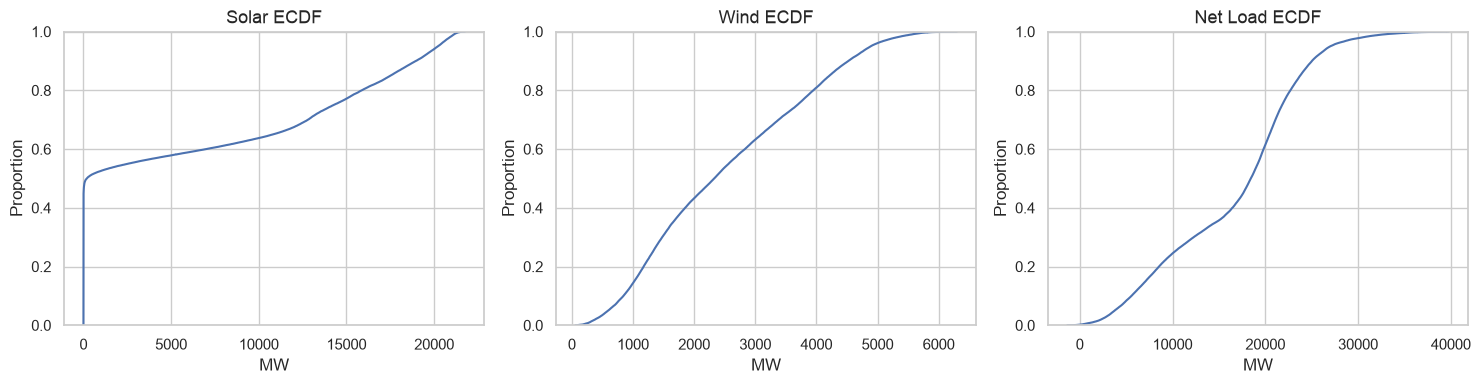

In [ ]:
# ECDFs expose tails without relying on a parametric family.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for metric, axis in zip(["solar", "wind", "net_load"], axes):
    sns.ecdfplot(data=production, x=metric, ax=axis)
    axis.set_title(f"{metric.replace('_', ' ').title()} ECDF")
    axis.set_xlabel("MW")
plt.tight_layout()
plt.show()

,count,mean,std,min,25%,50%,75%,max
load_less_generation_imports,"105,120.000",0.000,0.076,-9.317,-0.024,0.000,0.024,2.417
balance_recomputed,"105,120.000",0.000,0.076,-9.317,-0.024,0.000,0.024,2.417
balance_difference,"105,120.000",0.000,0.000,-0.000,0.000,0.000,0.000,0.000


Intervals with absolute source residual > 1 MW: 56
Negative net-load intervals: 217
Negative imports (net-export) intervals: 19861
Negative thermal intervals: 556


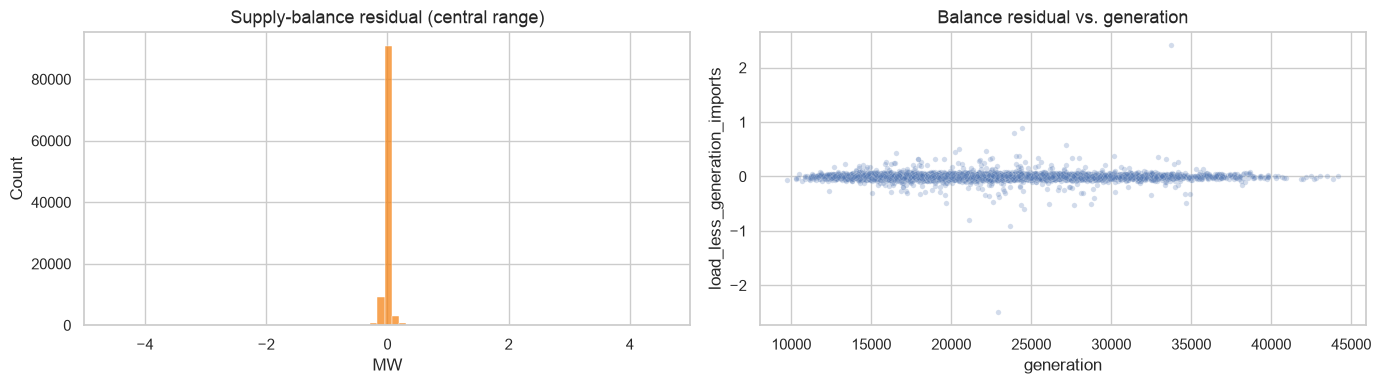

In [12]:
# Recompute the source balance field as a QA check.
production["balance_recomputed"] = production["load"] - (production["generation"] + production["imports"])
production["balance_difference"] = (
    production["balance_recomputed"] - production["load_less_generation_imports"]
)

balance_summary = production[["load_less_generation_imports", "balance_recomputed", "balance_difference"]].describe().T
display(balance_summary)
print("Intervals with absolute source residual > 1 MW:", int(production["load_less_generation_imports"].abs().gt(1).sum()))
print("Negative net-load intervals:", int(production["net_load"].lt(0).sum()))
print("Negative imports (net-export) intervals:", int(production["imports"].lt(0).sum()))
print("Negative thermal intervals:", int(production["thermal"].lt(0).sum()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(production["load_less_generation_imports"], bins=100, ax=axes[0], color="#F58518")
axes[0].set_xlim(-5, 5)
axes[0].set_title("Supply-balance residual (central range)")
axes[0].set_xlabel("MW")
sns.scatterplot(
    data=production.sample(min(5000, len(production)), random_state=RANDOM_SEED),
    x="generation", y="load_less_generation_imports", alpha=0.25, s=15, ax=axes[1]
)
axes[1].set_title("Balance residual vs. generation")
plt.tight_layout()
plt.show()

Negative imports normally mean net exports and should not be treated as invalid. Negative net load can occur when renewable output exceeds load. Negative thermal values are less physically intuitive and should be retained with a data-quality flag unless CAISO metadata supplies a correction rule. The very small balance residuals support broad aggregate analysis, but the raw/non-settlement warning remains applicable.

## 5. Energy conversion, seasonality, and the duck curve

In [13]:
# Each row is average MW over five minutes. Energy is MW × 5/60 hours.
for metric in production_metrics:
    production[f"{metric}_mwh"] = production[metric] * INTERVAL_HOURS

production["calendar_date"] = production["timestamp"].dt.date
production["month"] = production["timestamp"].dt.to_period("M").astype(str)
production["clock_hour"] = production["timestamp"].dt.hour
production["weekday"] = production["timestamp"].dt.day_name()
production["renewable_penetration"] = production["renewables"].div(production["load"].replace(0, np.nan))

annual_energy_twh = (
    production[[f"{metric}_mwh" for metric in production_metrics]].sum() / 1_000_000
).rename(index=lambda value: value.removesuffix("_mwh")).sort_values(ascending=False)
display(annual_energy_twh.to_frame("2025_energy_TWh"))

,2025_energy_TWh
load,225.041
generation,194.033
net_load,145.719
renewables,91.174
thermal,65.949
solar,57.245
imports,31.008
wind,22.077
large_hydro,19.300
nuclear,17.610


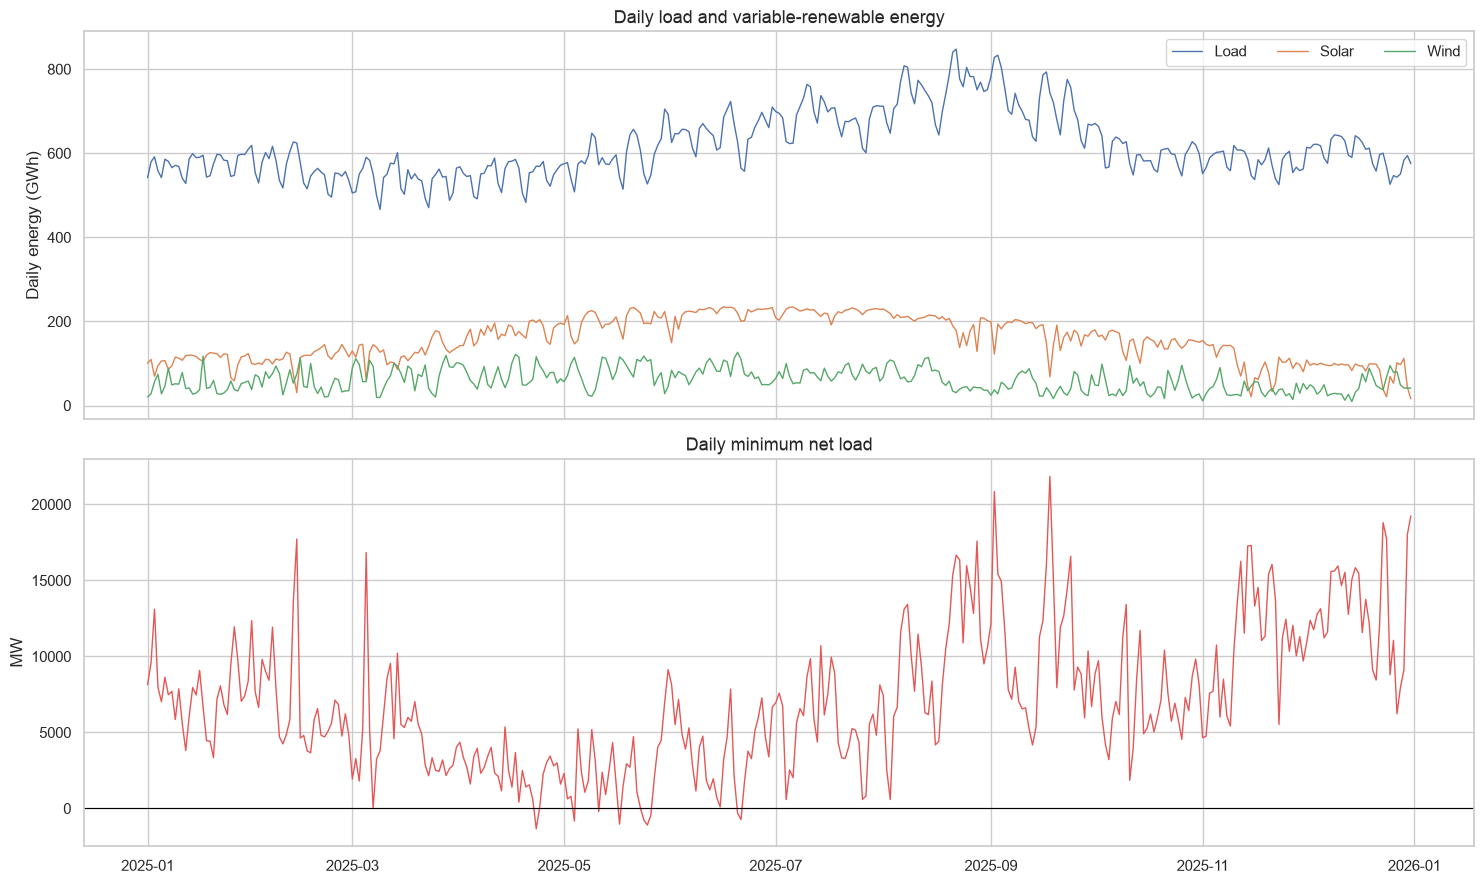

In [14]:
daily = production.groupby("calendar_date", as_index=False).agg(
    load_mwh=("load_mwh", "sum"),
    solar_mwh=("solar_mwh", "sum"),
    wind_mwh=("wind_mwh", "sum"),
    renewables_mwh=("renewables_mwh", "sum"),
    generation_mwh=("generation_mwh", "sum"),
    min_net_load_mw=("net_load", "min"),
    mean_net_load_mw=("net_load", "mean"),
    load_volatility_mw=("load", "std"),
    renewable_volatility_mw=("renewables", "std"),
    interval_count=("timestamp", "size"),
)
daily["calendar_date"] = pd.to_datetime(daily["calendar_date"])
daily["renewable_energy_share"] = daily["renewables_mwh"].div(daily["load_mwh"])

fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)
axes[0].plot(daily["calendar_date"], daily["load_mwh"] / 1000, label="Load", linewidth=1)
axes[0].plot(daily["calendar_date"], daily["solar_mwh"] / 1000, label="Solar", linewidth=1)
axes[0].plot(daily["calendar_date"], daily["wind_mwh"] / 1000, label="Wind", linewidth=1)
axes[0].set_ylabel("Daily energy (GWh)")
axes[0].set_title("Daily load and variable-renewable energy")
axes[0].legend(ncol=3)
axes[1].plot(daily["calendar_date"], daily["min_net_load_mw"], color="#E45756", linewidth=1)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("MW")
axes[1].set_title("Daily minimum net load")
plt.tight_layout()
plt.show()

,month,load_mwh,solar_mwh,wind_mwh,renewables_mwh,mean_net_load_mw,min_net_load_mw,renewable_share_of_load
0,2025-01,"17,846,183.391","3,323,035.404","1,465,188.537","5,798,502.377","17,551.021","3,347.036",0.325
1,2025-02,"15,664,159.736","3,185,416.823","1,601,623.105","5,687,601.676","16,186.190","3,658.693",0.363
2,2025-03,"16,662,890.008","3,953,558.758","2,262,267.348","7,175,353.818","14,060.651",5.292,0.431
3,2025-04,"16,493,804.459","5,244,796.437","2,190,666.487","8,353,432.413","12,581.030","-1,341.943",0.506
4,2025-05,"18,387,695.424","6,242,904.219","2,428,388.482","9,711,036.689","13,059.681","-1,094.775",0.528
5,2025-06,"19,478,170.383","6,629,868.592","2,395,817.634","10,086,204.546","14,517.339",-737.020,0.518
6,2025-07,"21,265,604.556","6,904,874.841","2,328,722.584","10,281,744.076","16,172.053",585.580,0.483
7,2025-08,"23,187,514.138","6,166,673.253","2,033,372.943","9,303,547.963","20,144.446",589.400,0.401
8,2025-09,"21,494,722.927","5,221,114.747","1,400,260.759","7,648,082.288","20,657.427","4,174.948",0.356
9,2025-10,"18,630,238.517","4,690,261.756","1,435,372.834","7,075,936.064","16,807.263","1,848.655",0.380


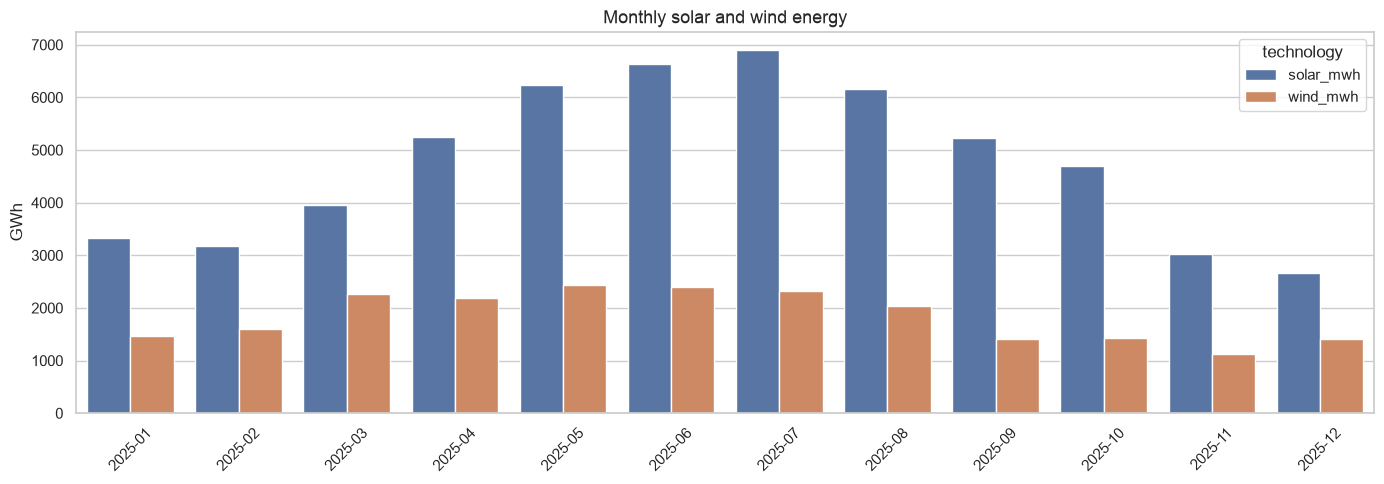

In [15]:
monthly = production.groupby("month", as_index=False).agg(
    load_mwh=("load_mwh", "sum"),
    solar_mwh=("solar_mwh", "sum"),
    wind_mwh=("wind_mwh", "sum"),
    renewables_mwh=("renewables_mwh", "sum"),
    mean_net_load_mw=("net_load", "mean"),
    min_net_load_mw=("net_load", "min"),
)
monthly["renewable_share_of_load"] = monthly["renewables_mwh"].div(monthly["load_mwh"])
display(monthly)

plot_monthly = monthly.melt(
    id_vars="month", value_vars=["solar_mwh", "wind_mwh"],
    var_name="technology", value_name="mwh"
)
plot_monthly["energy_gwh"] = plot_monthly["mwh"] / 1000
plt.figure(figsize=(14, 5))
sns.barplot(data=plot_monthly, x="month", y="energy_gwh", hue="technology")
plt.title("Monthly solar and wind energy")
plt.xlabel("")
plt.ylabel("GWh")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

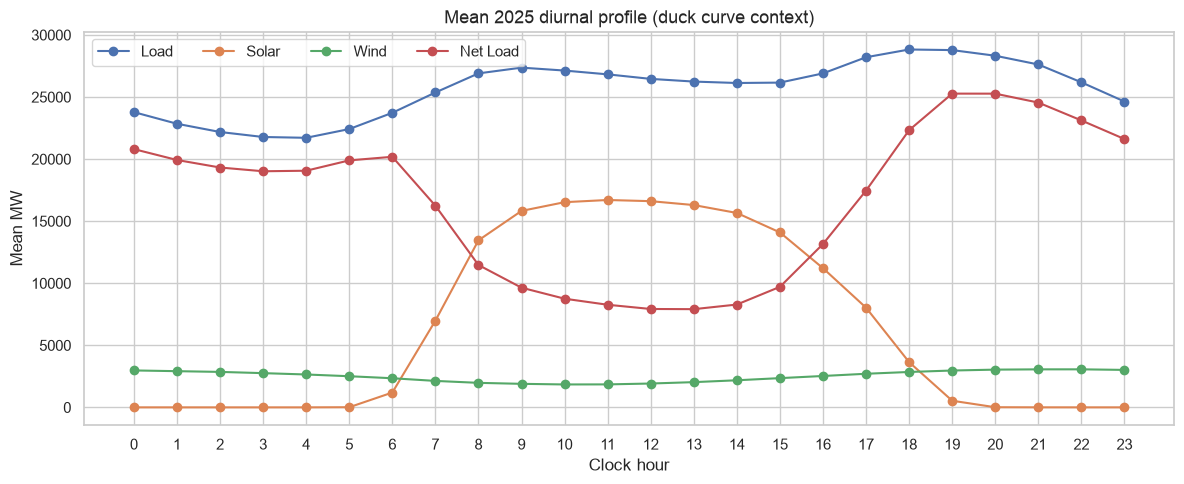

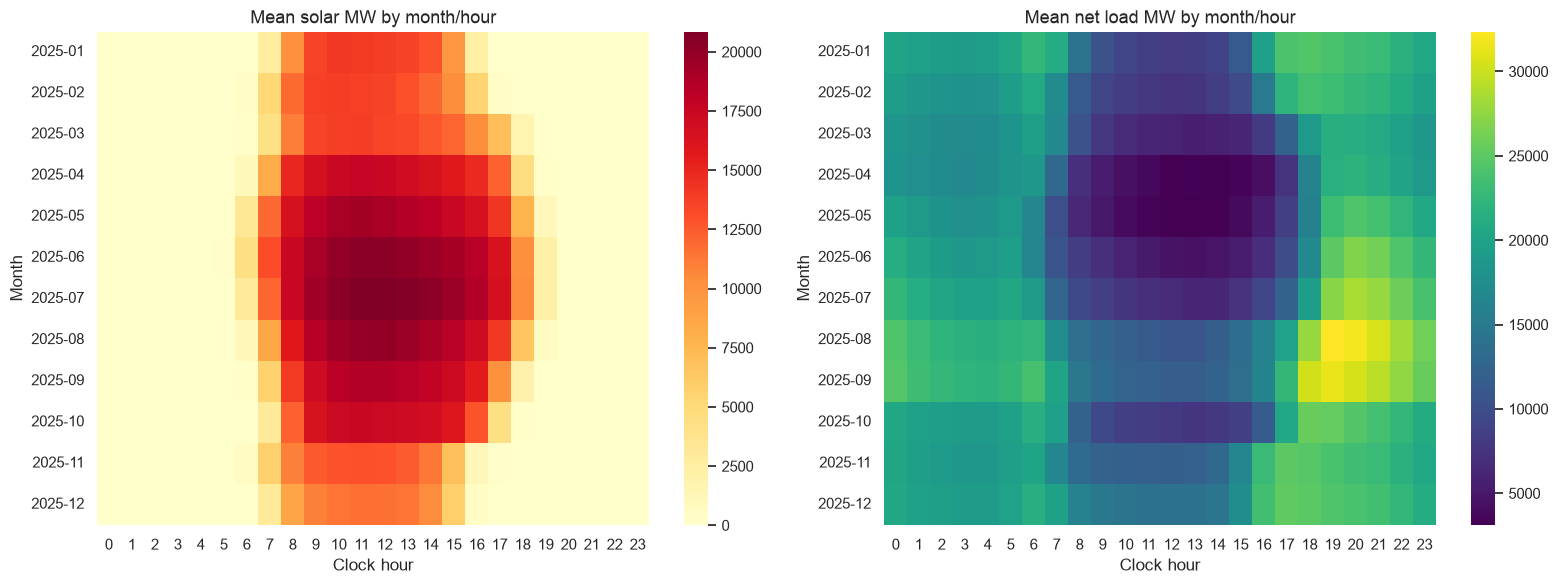

In [16]:
# Diurnal profiles and month-hour heatmaps reveal non-stationarity and the solar-driven duck curve.
diurnal = production.groupby("clock_hour", as_index=False)[["load", "solar", "wind", "net_load"]].mean()
plt.figure(figsize=(12, 5))
for metric in ["load", "solar", "wind", "net_load"]:
    plt.plot(diurnal["clock_hour"], diurnal[metric], marker="o", label=metric.replace("_", " ").title())
plt.xticks(range(24))
plt.xlabel("Clock hour")
plt.ylabel("Mean MW")
plt.title("Mean 2025 diurnal profile (duck curve context)")
plt.legend(ncol=4)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for metric, axis in [("solar", axes[0]), ("net_load", axes[1])]:
    heat = production.pivot_table(index="month", columns="clock_hour", values=metric, aggfunc="mean")
    sns.heatmap(heat, cmap="YlOrRd" if metric == "solar" else "viridis", ax=axis)
    axis.set_title(f"Mean {metric.replace('_', ' ')} MW by month/hour")
    axis.set_xlabel("Clock hour")
    axis.set_ylabel("Month")
plt.tight_layout()
plt.show()

## 6. Curtailment events, reasons, and distributions

In [17]:
curtailment_value_columns = ["wind_curtailment", "solar_curtailment"]
curtailment_reason_counts = curtailments["reason"].value_counts(dropna=False).rename("rows")
display(curtailment_reason_counts.to_frame())

curtailment_quality_flags = pd.Series({
    "negative_wind_values": int(curtailments["wind_curtailment"].dropna().lt(0).sum()),
    "negative_solar_values": int(curtailments["solar_curtailment"].dropna().lt(0).sum()),
    "rows_both_technology_values_missing": int(curtailments[curtailment_value_columns].isna().all(axis=1).sum()),
    "full_duplicate_rows": int(curtailments.duplicated().sum()),
    "unique_timestamps": int(curtailments["timestamp"].nunique()),
})
display(curtailment_quality_flags.to_frame("value"))

# Within reported rows only, a missing technology means no amount reported for that technology.
curt_work = curtailments.copy()
curt_work[curtailment_value_columns] = curt_work[curtailment_value_columns].fillna(0)
curt_work["wind_curtailed_mwh"] = curt_work["wind_curtailment"] * INTERVAL_HOURS
curt_work["solar_curtailed_mwh"] = curt_work["solar_curtailment"] * INTERVAL_HOURS

# Local and System rows can coexist at a timestamp; aggregate them before joining production.
curtailment_by_timestamp = curt_work.groupby("timestamp", as_index=False).agg(
    wind_curtailment_mw=("wind_curtailment", "sum"),
    solar_curtailment_mw=("solar_curtailment", "sum"),
    wind_curtailed_mwh=("wind_curtailed_mwh", "sum"),
    solar_curtailed_mwh=("solar_curtailed_mwh", "sum"),
    reason_row_count=("reason", "size"),
    reason_count=("reason", "nunique"),
)
print("Raw rows:", len(curt_work))
print("Unique aggregated timestamps:", len(curtailment_by_timestamp))
print("Timestamps with more than one reason row:", int(curtailment_by_timestamp["reason_row_count"].gt(1).sum()))
display(curtailment_by_timestamp.describe().T)

,rows
reason,
Local,20712
System,5136


,value
negative_wind_values,0
negative_solar_values,0
rows_both_technology_values_missing,0
full_duplicate_rows,0
unique_timestamps,21402


Raw rows: 25848
Unique aggregated timestamps: 21402
Timestamps with more than one reason row: 4446


,count,mean,min,25%,50%,75%,max,std
timestamp,21402,2025-03-29 08:28:33.821138,2025-01-01 10:30:00,2025-02-21 09:36:15,2025-04-06 09:57:30,2025-05-05 17:48:45,2025-05-31 19:30:00,NaN
wind_curtailment_mw,"21,402.000",123.548,0.000,0.000,69.017,178.749,"1,246.510",167.899
solar_curtailment_mw,"21,402.000","1,413.694",0.000,14.431,450.401,"2,063.330","9,969.417","1,989.253"
wind_curtailed_mwh,"21,402.000",10.296,0.000,0.000,5.751,14.896,103.876,13.992
solar_curtailed_mwh,"21,402.000",117.808,0.000,1.203,37.533,171.944,830.785,165.771
reason_row_count,"21,402.000",1.208,1.000,1.000,1.000,1.000,2.000,0.406
reason_count,"21,402.000",1.208,1.000,1.000,1.000,1.000,2.000,0.406


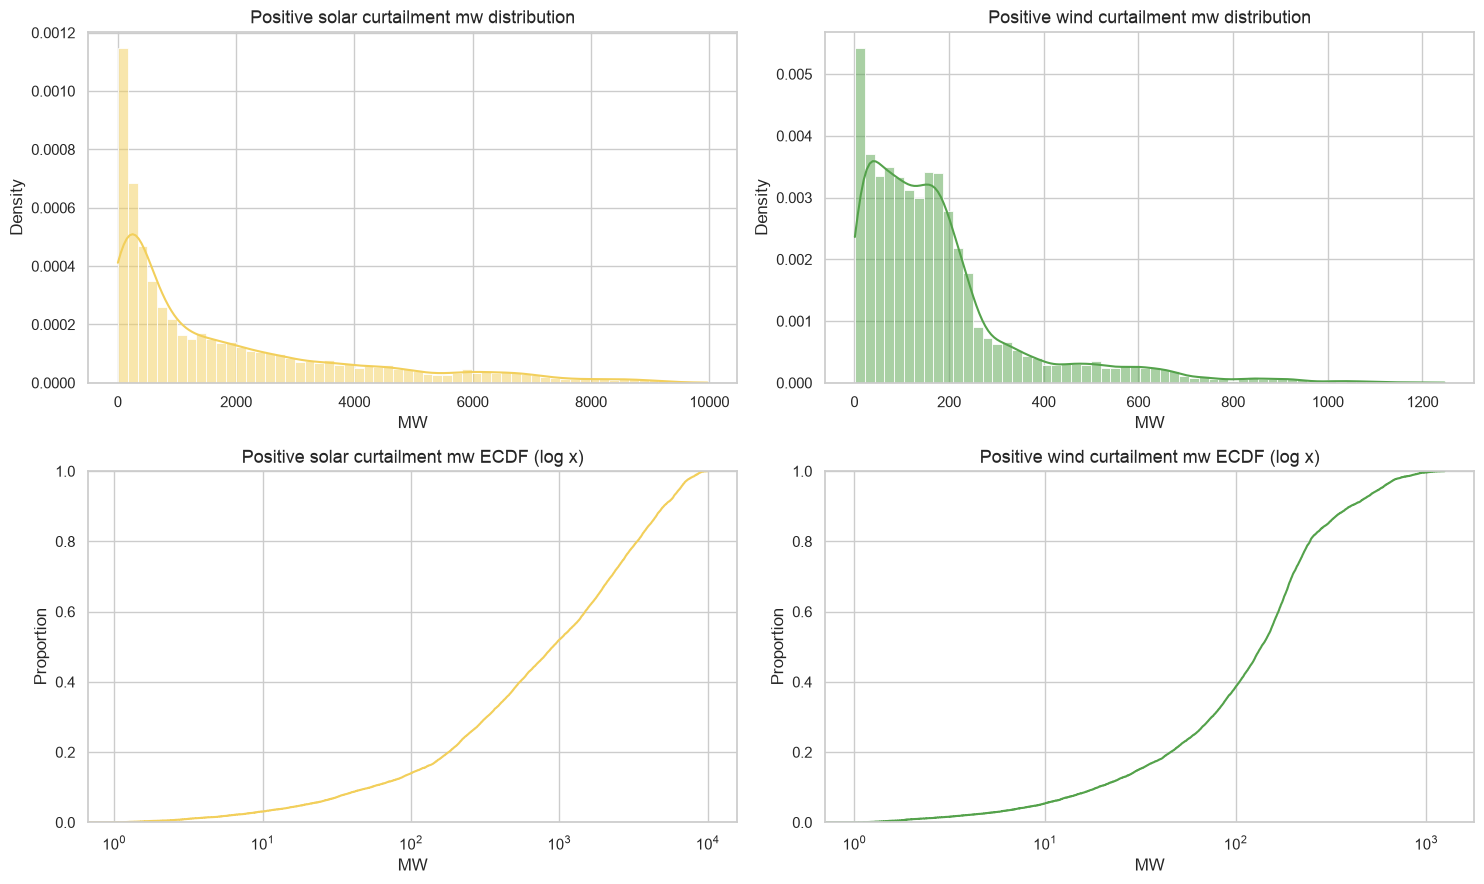

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for metric, axis, color in [
    ("solar_curtailment_mw", axes[0, 0], "#F2CF5B"),
    ("wind_curtailment_mw", axes[0, 1], "#54A24B"),
]:
    positive = curtailment_by_timestamp.loc[curtailment_by_timestamp[metric].gt(0), metric]
    sns.histplot(positive, bins=60, stat="density", kde=True, ax=axis, color=color)
    axis.set_title(f"Positive {metric.replace('_', ' ')} distribution")
    axis.set_xlabel("MW")
for metric, axis, color in [
    ("solar_curtailment_mw", axes[1, 0], "#F2CF5B"),
    ("wind_curtailment_mw", axes[1, 1], "#54A24B"),
]:
    positive = curtailment_by_timestamp.loc[curtailment_by_timestamp[metric].gt(0), metric]
    sns.ecdfplot(x=positive, ax=axis, color=color)
    axis.set_xscale("log")
    axis.set_title(f"Positive {metric.replace('_', ' ')} ECDF (log x)")
    axis.set_xlabel("MW")
plt.tight_layout()
plt.show()

,reason,solar_curtailed_mwh,wind_curtailed_mwh,rows
0,Local,"2,014,517.466","175,773.106",20712
1,System,"506,805.048","44,575.025",5136


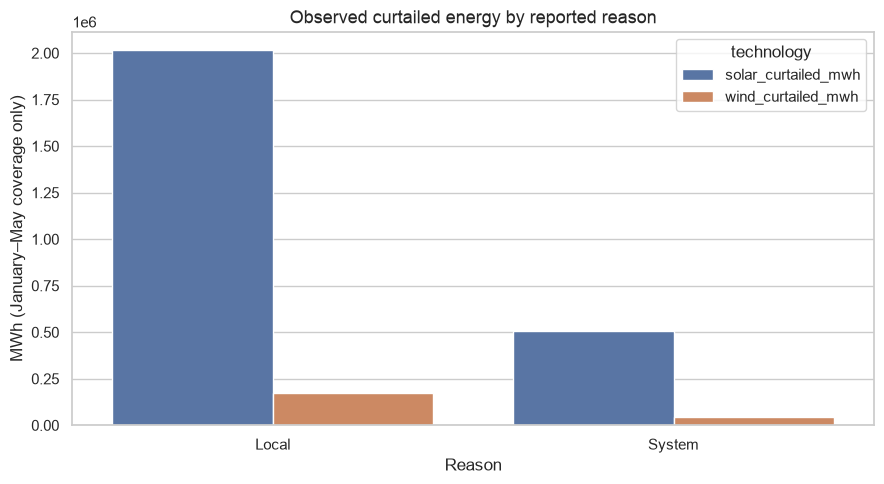

In [19]:
reason_energy = curt_work.groupby("reason", as_index=False).agg(
    solar_curtailed_mwh=("solar_curtailed_mwh", "sum"),
    wind_curtailed_mwh=("wind_curtailed_mwh", "sum"),
    rows=("reason", "size"),
)
reason_energy_long = reason_energy.melt(
    id_vars=["reason", "rows"],
    value_vars=["solar_curtailed_mwh", "wind_curtailed_mwh"],
    var_name="technology", value_name="curtailed_mwh",
)
display(reason_energy)
plt.figure(figsize=(9, 5))
sns.barplot(data=reason_energy_long, x="reason", y="curtailed_mwh", hue="technology")
plt.title("Observed curtailed energy by reported reason")
plt.xlabel("Reason")
plt.ylabel("MWh (January–May coverage only)")
plt.tight_layout()
plt.show()

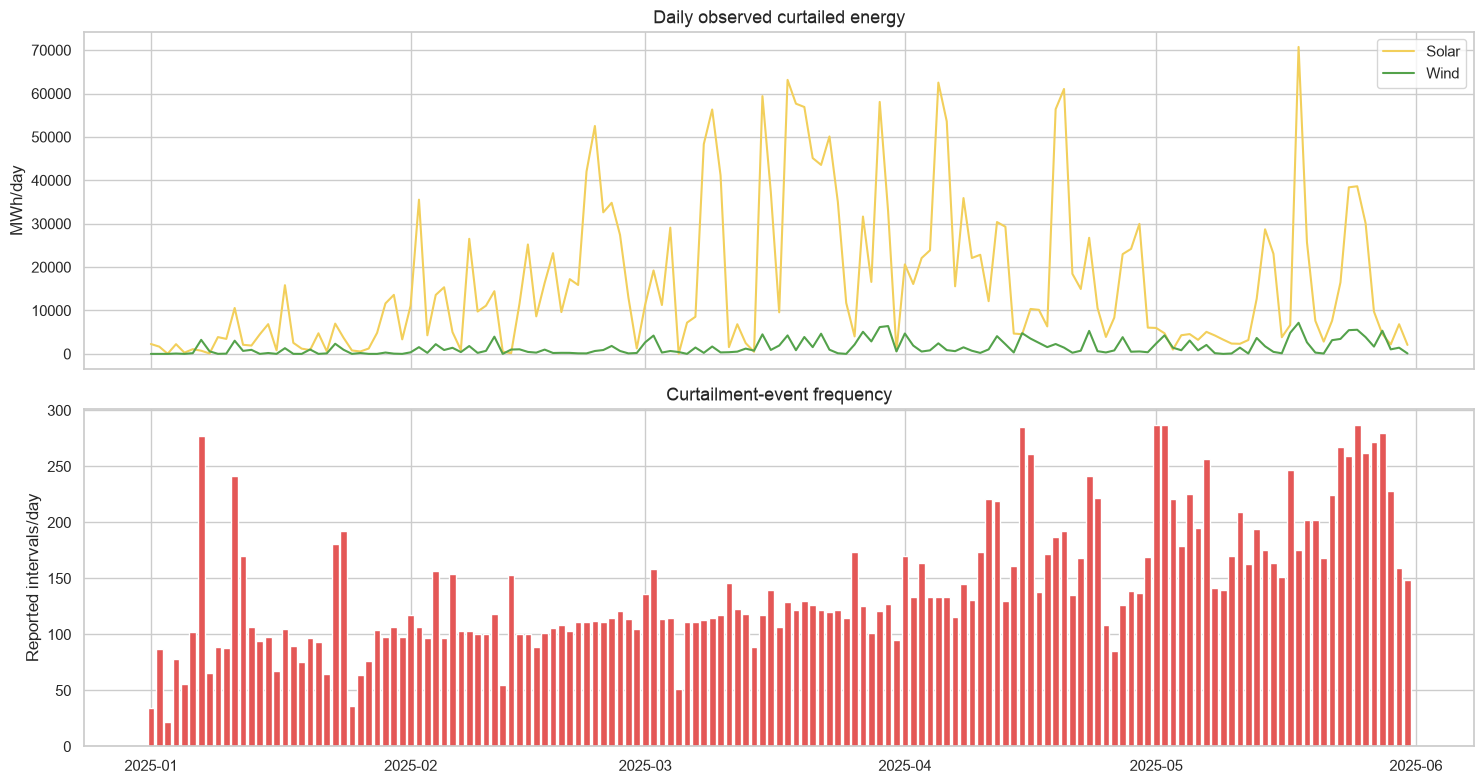

In [20]:
curtailment_by_timestamp["calendar_date"] = curtailment_by_timestamp["timestamp"].dt.floor("D")
daily_curtailment = curtailment_by_timestamp.groupby("calendar_date", as_index=False).agg(
    solar_curtailed_mwh=("solar_curtailed_mwh", "sum"),
    wind_curtailed_mwh=("wind_curtailed_mwh", "sum"),
    curtailed_interval_count=("timestamp", "size"),
    max_solar_curtailment_mw=("solar_curtailment_mw", "max"),
    max_wind_curtailment_mw=("wind_curtailment_mw", "max"),
)

fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
axes[0].plot(daily_curtailment["calendar_date"], daily_curtailment["solar_curtailed_mwh"], label="Solar", color="#F2CF5B")
axes[0].plot(daily_curtailment["calendar_date"], daily_curtailment["wind_curtailed_mwh"], label="Wind", color="#54A24B")
axes[0].set_ylabel("MWh/day")
axes[0].set_title("Daily observed curtailed energy")
axes[0].legend()
axes[1].bar(daily_curtailment["calendar_date"], daily_curtailment["curtailed_interval_count"], color="#E45756")
axes[1].set_ylabel("Reported intervals/day")
axes[1].set_title("Curtailment-event frequency")
plt.tight_layout()
plt.show()

## 7. Joint production–curtailment analysis and QA flags

In [21]:
coverage_start = curtailment_by_timestamp["timestamp"].min()
coverage_end = curtailment_by_timestamp["timestamp"].max()
production_in_coverage = production.loc[
    production["timestamp"].between(coverage_start, coverage_end),
    ["timestamp", "solar", "wind", "load", "net_load", "renewables", "solar_mwh", "wind_mwh", "load_mwh", "renewables_mwh"]
].copy()

# During the observed coverage only, a missing event row can represent no reported curtailment.
joint = production_in_coverage.merge(curtailment_by_timestamp, on="timestamp", how="left")
fill_columns = [
    "solar_curtailment_mw", "wind_curtailment_mw", "solar_curtailed_mwh",
    "wind_curtailed_mwh", "reason_row_count", "reason_count",
]
joint[fill_columns] = joint[fill_columns].fillna(0)
joint["solar_available_proxy_mw"] = joint["solar"] + joint["solar_curtailment_mw"]
joint["wind_available_proxy_mw"] = joint["wind"] + joint["wind_curtailment_mw"]
joint["solar_curtailment_share"] = joint["solar_curtailment_mw"].div(joint["solar_available_proxy_mw"].replace(0, np.nan))
joint["wind_curtailment_share"] = joint["wind_curtailment_mw"].div(joint["wind_available_proxy_mw"].replace(0, np.nan))
joint["raw_solar_curtailment_to_production"] = joint["solar_curtailment_mw"].div(joint["solar"].replace(0, np.nan))

print("Joint-analysis window:", coverage_start, "to", coverage_end)
print("Production rows in window:", len(joint))
print("Rows with reported curtailment:", int(joint["reason_row_count"].gt(0).sum()))
print("Raw solar curtailment / production > 1 flags:", int(joint["raw_solar_curtailment_to_production"].gt(1).sum()))
print("Solar available-proxy share outside [0,1]:", int((~joint["solar_curtailment_share"].between(0, 1) & joint["solar_curtailment_share"].notna()).sum()))

display(joint[[
    "solar", "wind", "net_load", "solar_curtailment_mw", "wind_curtailment_mw",
    "solar_curtailment_share", "wind_curtailment_share"
]].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).T)

Joint-analysis window: 2025-01-01 10:30:00 to 2025-05-31 19:30:00
Production rows in window: 43297
Rows with reported curtailment: 21402
Raw solar curtailment / production > 1 flags: 30
Solar available-proxy share outside [0,1]: 0


,count,mean,std,min,50%,90%,95%,99%,max
solar,"43,297.000","6,074.414","7,266.628",0.000,139.680,"16,859.798","18,701.958","20,686.961","21,556.170"
wind,"43,297.000","2,750.978","1,424.466",114.152,"2,692.380","4,709.686","5,055.882","5,616.060","6,295.463"
net_load,"43,297.000","14,646.707","7,198.806","-1,341.943","17,246.145","22,706.171","24,062.419","26,195.095","33,372.749"
solar_curtailment_mw,"43,297.000",698.798,"1,567.025",0.000,0.000,"2,626.975","4,470.469","7,249.555","9,969.417"
wind_curtailment_mw,"43,297.000",61.071,133.229,0.000,0.000,200.269,309.218,655.984,"1,246.510"
solar_curtailment_share,"24,368.000",0.069,0.102,0.000,0.019,0.224,0.314,0.409,1.000
wind_curtailment_share,"43,297.000",0.020,0.041,0.000,0.000,0.068,0.108,0.189,0.434


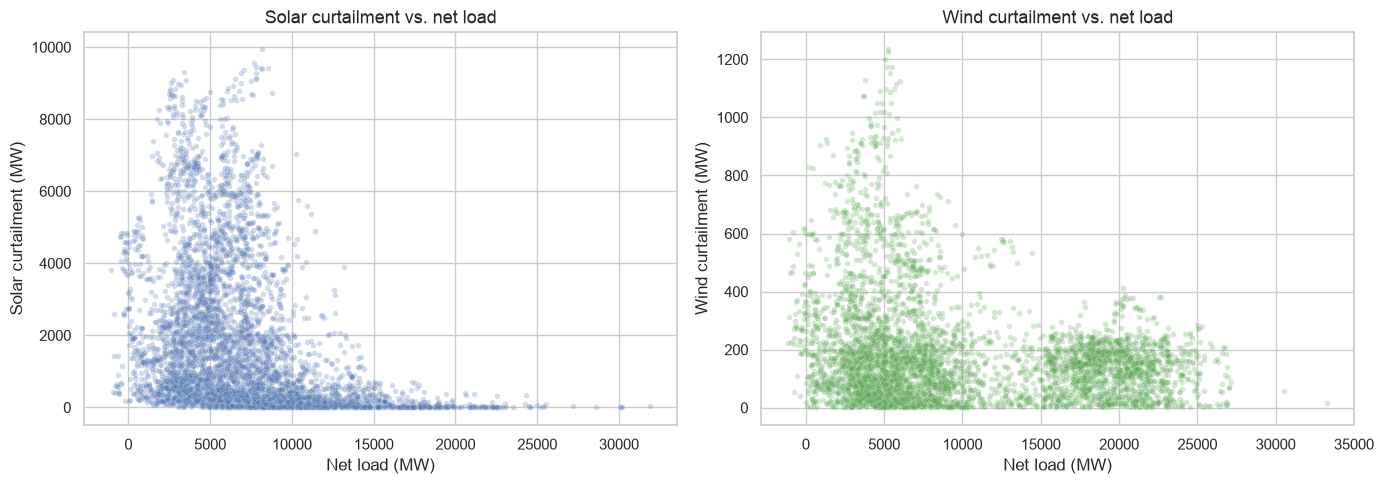

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(
    data=joint.loc[joint["solar_curtailment_mw"].gt(0)].sample(
        min(5000, int(joint["solar_curtailment_mw"].gt(0).sum())), random_state=RANDOM_SEED
    ),
    x="net_load", y="solar_curtailment_mw", alpha=0.25, s=16, ax=axes[0]
)
axes[0].set_title("Solar curtailment vs. net load")
axes[0].set_xlabel("Net load (MW)")
axes[0].set_ylabel("Solar curtailment (MW)")
sns.scatterplot(
    data=joint.loc[joint["wind_curtailment_mw"].gt(0)].sample(
        min(5000, int(joint["wind_curtailment_mw"].gt(0).sum())), random_state=RANDOM_SEED
    ),
    x="net_load", y="wind_curtailment_mw", alpha=0.25, s=16, color="#54A24B", ax=axes[1]
)
axes[1].set_title("Wind curtailment vs. net load")
axes[1].set_xlabel("Net load (MW)")
axes[1].set_ylabel("Wind curtailment (MW)")
plt.tight_layout()
plt.show()

The available-generation proxy (`production + curtailment`) is suitable for descriptive system-level intensity, not a plant-level engineering quantity. Ratios above one when curtailed MW is divided only by produced MW are possible and are flagged rather than deleted. They do not prove bad data because curtailment and delivered production are different quantities, but they reinforce the need to avoid interpreting the ratio as project-specific performance.

## 8. Serial dependence and leakage-safe aggregation

,lag_1_days,lag_7_days,lag_14_days,lag_30_days
load_mwh,0.906,0.838,0.807,0.524
solar_mwh,0.908,0.831,0.775,0.679
wind_mwh,0.626,0.268,0.182,0.247
min_net_load_mw,0.781,0.597,0.535,0.333


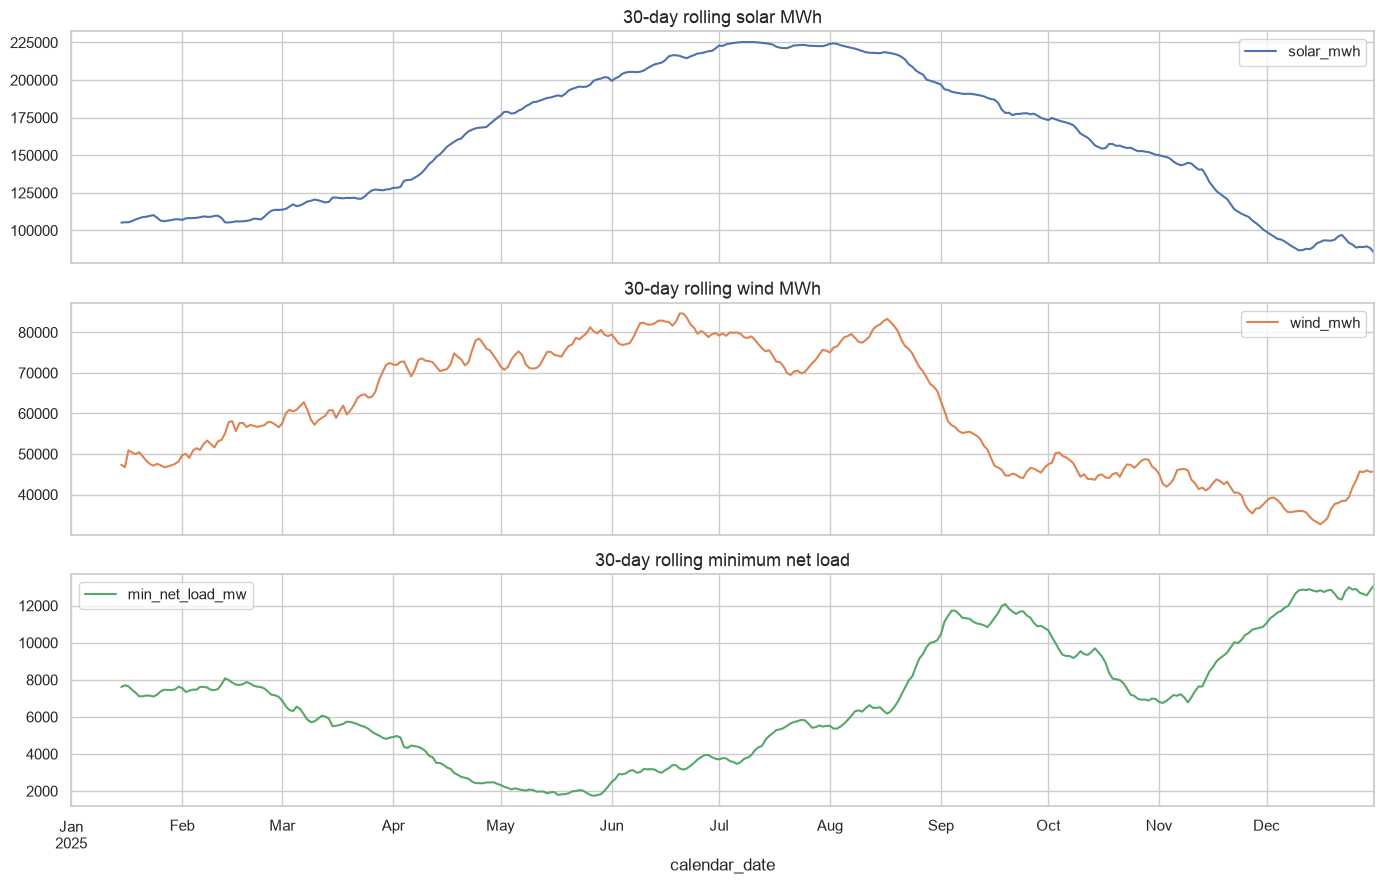

In [23]:
# Daily autocorrelation: high dependence means random row splits would leak temporal structure.
autocorrelation_metrics = ["load_mwh", "solar_mwh", "wind_mwh", "min_net_load_mw"]
autocorrelation_lags = [1, 7, 14, 30]
autocorrelation = pd.DataFrame(
    {
        metric: {f"lag_{lag}_days": daily[metric].autocorr(lag=lag) for lag in autocorrelation_lags}
        for metric in autocorrelation_metrics
    }
).T
display(autocorrelation)

rolling_view = daily.set_index("calendar_date")[["solar_mwh", "wind_mwh", "min_net_load_mw"]].rolling(30, min_periods=15).mean()
rolling_view.plot(subplots=True, figsize=(14, 9), title=[
    "30-day rolling solar MWh", "30-day rolling wind MWh", "30-day rolling minimum net load"
])
plt.tight_layout()
plt.show()

In [24]:
# Example feature table for dates with measured curtailment coverage.
# shift(1) ensures a feature for prediction date t uses information through t-1 only.
daily_context = daily.set_index("calendar_date").copy()
daily_curt = daily_curtailment.set_index("calendar_date").copy()
daily_context = daily_context.join(daily_curt, how="left")
observed_curtailment_days = daily_context.index.to_series().between(coverage_start.floor("D"), coverage_end.floor("D"))
curtailment_daily_columns = ["solar_curtailed_mwh", "wind_curtailed_mwh", "curtailed_interval_count"]
daily_context.loc[observed_curtailment_days, curtailment_daily_columns] = (
    daily_context.loc[observed_curtailment_days, curtailment_daily_columns].fillna(0)
)

feature_source_columns = [
    "solar_mwh", "wind_mwh", "renewables_mwh", "min_net_load_mw",
    "load_volatility_mw", "renewable_volatility_mw",
    "solar_curtailed_mwh", "wind_curtailed_mwh", "curtailed_interval_count",
]
feature_table = pd.DataFrame(index=daily_context.index)
for window in [30, 90]:
    past_only = daily_context[feature_source_columns].shift(1).rolling(window, min_periods=window)
    means = past_only.mean().add_suffix(f"_trailing_{window}d_mean")
    sums = past_only.sum().add_suffix(f"_trailing_{window}d_sum")
    feature_table = feature_table.join(means).join(sums)

feature_table = feature_table.loc[feature_table.index <= coverage_end.floor("D")]
print("Illustrative as-of feature table shape:", feature_table.shape)
display(feature_table.tail(3).T)

Illustrative as-of feature table shape: (151, 36)


calendar_date,2025-05-29,2025-05-30,2025-05-31
solar_mwh_trailing_30d_mean,"200,478.285","201,005.860","201,921.013"
wind_mwh_trailing_30d_mean,"79,786.988","80,609.531","79,435.103"
renewables_mwh_trailing_30d_mean,"313,765.131","315,150.927","314,910.196"
min_net_load_mw_trailing_30d_mean,"1,784.728","1,834.219","2,013.145"
load_volatility_mw_trailing_30d_mean,"2,098.404","2,125.667","2,207.009"
renewable_volatility_mw_trailing_30d_mean,"7,951.007","7,948.727","7,969.254"
solar_curtailed_mwh_trailing_30d_mean,"13,592.413","12,666.615","12,692.584"
wind_curtailed_mwh_trailing_30d_mean,"2,240.294","2,256.317","2,291.299"
curtailed_interval_count_trailing_30d_mean,210.300,213.333,213.000
solar_mwh_trailing_30d_sum,"6,014,348.558","6,030,175.798","6,057,630.391"


### How these features could be joined safely

For a queue project with prediction cutoff date `t`, compute trailing context using records timestamped **strictly before `t`**, then perform an as-of join. Candidate system-context features include trailing 30/90/180/365-day solar and wind curtailed MWh, curtailment-event frequency, Local/System shares, renewable penetration, minimum net load, and load/renewable volatility.

Leakage controls:
- never attach full-year 2025 totals to a project whose cutoff predates those measurements;
- split model evaluation by time (and preferably by queue cohort), not random five-minute rows;
- do not fill months outside measured curtailment coverage with zero;
- use solar context only for solar/hybrid projects and wind context only for wind/hybrid projects;
- fit transformations on training periods only;
- include a coverage/availability indicator whenever contextual features can be missing.

## 9. What this dataset can and cannot explain

In [25]:
assessment = pd.DataFrame([
    {
        "use_case": "Primary project classifier training",
        "assessment": "No",
        "reason": "No project identifier, queue status, terminal outcome, POI, county, study result, upgrade cost, or project-level timeline."
    },
    {
        "use_case": "Historical classifier context",
        "assessment": "Not yet",
        "reason": "Only one production year and roughly five months of curtailment; most historical queue outcomes cannot receive leakage-safe as-of features."
    },
    {
        "use_case": "Future/recent project context",
        "assessment": "Conditional",
        "reason": "Useful after multiple historical years are acquired and features are joined as-of by prediction date; system-wide context remains coarse."
    },
    {
        "use_case": "SQL analytics",
        "assessment": "Yes",
        "reason": "Supports interval, daily, monthly, technology, net-load, and curtailment summaries with explicit coverage metadata."
    },
    {
        "use_case": "RAG / agent explanations",
        "assessment": "Yes, with caveats",
        "reason": "Can ground statements about 2025 CAISO operating conditions, seasonality, duck-curve patterns, and observed curtailment—not project causality."
    },
])
display(assessment.style.hide(axis="index"))

use_case,assessment,reason
Primary project classifier training,No,"No project identifier, queue status, terminal outcome, POI, county, study result, upgrade cost, or project-level timeline."
Historical classifier context,Not yet,Only one production year and roughly five months of curtailment; most historical queue outcomes cannot receive leakage-safe as-of features.
Future/recent project context,Conditional,Useful after multiple historical years are acquired and features are joined as-of by prediction date; system-wide context remains coarse.
SQL analytics,Yes,"Supports interval, daily, monthly, technology, net-load, and curtailment summaries with explicit coverage metadata."
RAG / agent explanations,"Yes, with caveats","Can ground statements about 2025 CAISO operating conditions, seasonality, duck-curve patterns, and observed curtailment—not project causality."


This workbook describes **system operating conditions**, not interconnection decisions. It can reveal when CAISO experienced low net load or renewable curtailment, but it cannot establish why a specific solar or wind project was withdrawn, delayed, approved, or placed in service. Those outcomes may reflect interconnection costs, study results, deliverability, permitting, financing, site control, procurement, developer strategy, or local transmission constraints—none of which are identified here. “Local” versus “System” is still an ISO-level reason category and is not a project/POI linkage.

Correlations between curtailment and net load are descriptive, not causal evidence about queue withdrawal. A system-wide aggregate can also hide geographically local congestion that matters to a particular POI.

## 10. Final determination and recommendations

In [26]:
coverage_days = (coverage_end.floor("D") - coverage_start.floor("D")).days + 1
production_nulls = int(production.isna().sum().sum())
curtailment_nulls = int(curtailments[curtailment_value_columns].isna().sum().sum())
annual_solar_twh = float(annual_energy_twh["solar"])
annual_wind_twh = float(annual_energy_twh["wind"])
observed_solar_curtailment_mwh = float(curtailment_by_timestamp["solar_curtailed_mwh"].sum())
observed_wind_curtailment_mwh = float(curtailment_by_timestamp["wind_curtailed_mwh"].sum())

summary_text = f'''
### Evidence-based result

- All **{len(sheet_names)} sheets** were loaded: `{', '.join(sheet_names)}`.
- Production has **{len(production):,}** five-minute observations and **{production_nulls:,}** null cells. Its row count equals a 365-day five-minute year, with the expected spring/fall DST pattern: **{len(missing_wall_clock)}** missing and **{len(duplicated_wall_clock)}** duplicated wall-clock rows.
- Curtailment has **{len(curtailments):,}** event rows across **{curtailment_by_timestamp['timestamp'].nunique():,}** unique timestamps, covering only **{coverage_days} calendar days** ({coverage_start:%Y-%m-%d} through {coverage_end:%Y-%m-%d}). Its technology-field nulls (**{curtailment_nulls:,}**) are structural within event rows.
- Approximate 2025 delivered production is **{annual_solar_twh:,.1f} TWh solar** and **{annual_wind_twh:,.1f} TWh wind**. Observed January–May curtailed energy totals **{observed_solar_curtailment_mwh:,.0f} MWh solar** and **{observed_wind_curtailment_mwh:,.0f} MWh wind**; these are not full-year totals.

### ML decision

**Do not use this workbook as a direct training table or label source for the primary binary classifier.** It has neither project-level rows nor the terminal operational/withdrawn target. The primary model should be trained on the project-level queue dataset, with active projects treated as censored/unlabeled rather than negative outcomes.

The workbook is **not presently necessary for a viable baseline classifier**. Build the first model from leakage-screened project attributes available at the prediction cutoff. Add production/curtailment context only as an optional second-stage experiment after acquiring multiple historical years and implementing date-safe as-of joins. Keep the feature block only if out-of-time validation demonstrates incremental benefit and adequate coverage.

### Project recommendations

1. **Primary ML:** predict `eventual operational before withdrawal` among mature/terminal cohorts; report calibration and class-sensitive metrics, and handle still-active projects through censoring or a fixed outcome window.
2. **Optional second model:** consider survival/time-to-event modeling for time to commercial operation or withdrawal, because the agent also needs a timetable. Queue milestones and censoring are much more relevant than this workbook alone.
3. **Data acquisition:** prioritize project-level study results, upgrade costs, POI/transmission-zone constraints, permitting, milestones, and historical CAISO production/curtailment years aligned to queue dates.
4. **SQL:** store interval timestamps, MW/MWh units, reason, source coverage start/end, and QA flags. Preserve duplicate DST observations with a stable sequence or timezone-aware key.
5. **RAG/agent:** use these results for bounded statements about 2025 system context. The agent must disclose that aggregate curtailment does not explain an individual project's queue outcome.

**Bottom line:** retain this workbook for descriptive analytics and RAG/agent context, but exclude it from the initial project-outcome classifier. Reconsider it as a contextual feature source only when sufficient historical coverage and defensible temporal joins exist.
'''
display(Markdown(summary_text))


### Evidence-based result

- All **3 sheets** were loaded: `Read_me, Production, Curtailments`.
- Production has **105,120** five-minute observations and **0** null cells. Its row count equals a 365-day five-minute year, with the expected spring/fall DST pattern: **12** missing and **24** duplicated wall-clock rows.
- Curtailment has **25,848** event rows across **21,402** unique timestamps, covering only **151 calendar days** (2025-01-01 through 2025-05-31). Its technology-field nulls (**14,611**) are structural within event rows.
- Approximate 2025 delivered production is **57.2 TWh solar** and **22.1 TWh wind**. Observed January–May curtailed energy totals **2,521,323 MWh solar** and **220,348 MWh wind**; these are not full-year totals.

### ML decision

**Do not use this workbook as a direct training table or label source for the primary binary classifier.** It has neither project-level rows nor the terminal operational/withdrawn target. The primary model should be trained on the project-level queue dataset, with active projects treated as censored/unlabeled rather than negative outcomes.

The workbook is **not presently necessary for a viable baseline classifier**. Build the first model from leakage-screened project attributes available at the prediction cutoff. Add production/curtailment context only as an optional second-stage experiment after acquiring multiple historical years and implementing date-safe as-of joins. Keep the feature block only if out-of-time validation demonstrates incremental benefit and adequate coverage.

### Project recommendations

1. **Primary ML:** predict `eventual operational before withdrawal` among mature/terminal cohorts; report calibration and class-sensitive metrics, and handle still-active projects through censoring or a fixed outcome window.
2. **Optional second model:** consider survival/time-to-event modeling for time to commercial operation or withdrawal, because the agent also needs a timetable. Queue milestones and censoring are much more relevant than this workbook alone.
3. **Data acquisition:** prioritize project-level study results, upgrade costs, POI/transmission-zone constraints, permitting, milestones, and historical CAISO production/curtailment years aligned to queue dates.
4. **SQL:** store interval timestamps, MW/MWh units, reason, source coverage start/end, and QA flags. Preserve duplicate DST observations with a stable sequence or timezone-aware key.
5. **RAG/agent:** use these results for bounded statements about 2025 system context. The agent must disclose that aggregate curtailment does not explain an individual project's queue outcome.

**Bottom line:** retain this workbook for descriptive analytics and RAG/agent context, but exclude it from the initial project-outcome classifier. Reconsider it as a contextual feature source only when sufficient historical coverage and defensible temporal joins exist.


## Reproducibility checklist

- Every workbook sheet was loaded and documented.
- Column names were normalized before analysis.
- Timestamp semantics were validated against redundant Hour/Interval fields.
- MW was converted to MWh with `5/60`, not summed as if already energy.
- DST duplicates were retained and disclosed.
- Curtailment reason rows were aggregated before joining production.
- Partial curtailment coverage was not imputed as zero outside its observed period.
- Feature examples use past-only rolling windows.
- No supplementary analysis files are created by this notebook.

## How the agent can use production and curtailment system context

The limited overlap does not eliminate the data’s value for SQL and RAG, because those components serve a different purpose from the ML classifier. It does, however, reinforce the recommendation not to use these variables in the initial model.

### Recommended agent architecture

The agent should distinguish three kinds of evidence:

1. **ML model:** project-specific probability of eventual operation before withdrawal.
2. **SQL:** computed project, cohort, and CAISO system statistics.
3. **RAG:** definitions, methodology, regulatory context, and interpretation limitations.

The agent must not present system context as though it caused or materially changed the ML probability unless those features were actually included and validated in the model.

### How SQL could add context

Store the five-minute records in SQL, but expose daily, monthly, and trailing-period views. For a solar project, the agent could query:

- Trailing 12-month solar curtailed MWh
- Solar curtailment as a percentage of available solar energy
- Number of solar-curtailment intervals
- Local versus System curtailment proportions
- Solar production and renewable penetration
- Frequency of negative or unusually low net load
- Year-over-year curtailment trends
- Comparison with other years from 2020–2025

For example, a user could ask:

> What were CAISO-wide solar operating conditions around this project’s queue-entry date?

The agent could respond with factual SQL results:

> During the 12 months preceding the project’s application, CAISO experienced X GWh of reported solar curtailment, Y% more than the preceding year. Most curtailment was classified as Local/System.

That is useful context even if it is not a model feature.

### How the agent could use that context

Elevated solar curtailment could prompt the agent to recommend additional diligence concerning:

- POI-specific congestion
- Deliverability status
- Network-upgrade requirements
- Storage or hybridization
- Expected capture prices and project economics
- Whether the developer has accounted for curtailment risk

The defensible interpretation is:

> System-wide conditions suggest increasing operational pressure for solar resources. This does not establish that the proposed project’s POI is constrained or that the project will be withdrawn.

It should not say:

> High CAISO curtailment means this project is unlikely to interconnect.

The latter inference is unsupported.

### Appropriate role for RAG

RAG should not contain every five-minute measurement. SQL is better for numerical time-series retrieval.

RAG should contain:

- Definitions of production, curtailment, net load, and renewable penetration
- Explanations of Local versus System curtailment
- CAISO source documentation and data-quality warnings
- Descriptions of plausible relationships between congestion, project economics, and withdrawal
- Explicit limitations of statewide aggregate measurements
- Documentation of coverage dates and calculation methodology

SQL supplies the numbers; RAG helps the agent interpret those numbers correctly.

### Example agent answer

A well-structured answer might be:

> The project-level model estimates a 64% probability of becoming operational before withdrawal. This estimate is based on project and queue characteristics; CAISO production and curtailment were not model inputs.
>
> As supplementary system context, CAISO solar curtailment increased during the period surrounding the application. That trend may indicate growing system-wide oversupply or transmission pressure, but the available data do not identify conditions at this project’s POI. POI-specific study results and upgrade costs should be reviewed before interpreting this as additional project risk.

That clearly separates the prediction from contextual evidence.

### Effect of the 2000–2025 versus 2020–2025 coverage

For projects entering before 2020:

- No contemporaneous production/curtailment context is available.
- The agent should return “system context unavailable,” not substitute 2020–2025 values.

For projects entering during 2020:

- A full trailing 12-month calculation is unavailable without 2019 data.
- Shorter windows or explicit partial-coverage flags are required.

For projects entering during 2021–2025:

- Leakage-safe trailing system metrics can be calculated.
- Many recent projects remain active, so terminal outcome labels may still be immature.

For a new project evaluated after 2025:

- The agent can describe the latest available conditions.
- It must state that the system dataset ends in 2025 and may be stale.
- A production pipeline should eventually update these tables regularly.

Although the time overlap is only six years, recent years may contain many projects because queue volume increased substantially. The real eligibility question is not merely the number of overlapping years; it is how many overlapping CAISO solar projects have mature operational or withdrawn outcomes. That count should be measured before considering model inclusion.

### Revised recommendation

- **ML classifier:** exclude production and curtailment from the initial model.
- **SQL:** retain them for calculated system trends and period-specific context.
- **RAG:** retain documentation, interpretations, and limitations—not raw interval data.
- **Agent:** present the results as supplementary system context and diligence prompts, clearly separated from the project-level probability.
- **Future ML experiment:** test trailing monthly features only if enough 2020–2025 projects have mature terminal outcomes, using time-based validation against a project-only baseline.

The limited overlap weakens their suitability for supervised training, but it does not weaken their usefulness as transparent contextual evidence delivered through SQL and RAG.